# 📚 Spooky Author Identification — Çok Sınıflı Metin Sınıflandırma

## 🎯 Problem
Bu notebook'ta üç farklı korku edebiyatı yazarına (EAP, HPL, MWS) ait metinlerden **yazarı tahmin ediyoruz**. Çok sınıflı (multi-class) metin sınıflandırma problemidir.

## 💡 Bu notebook'tan ne öğrenirsin?
- TF-IDF ile metin vektörleştirme (n-gram, sublinear_tf, min_df parametreleri)
- Sızıntısız (leakage-free) pipeline: TF-IDF SADECE train verisiyle fit edilir
- Sınıf bazlı en karakteristik kelimeleri keşfetme
- Confusion Matrix ve Classification Report yorumlama
- Cross-validation ile gerçek model performansını ölçme

## 📊 Veri Seti
- **Kaynak:** [Kaggle - Spooky Author Identification](https://www.kaggle.com/c/spooky-author-identification)
- **Boyut:** ~19.579 cümle
- **Hedef:** EAP (Edgar Allan Poe), HPL (H.P. Lovecraft), MWS (Mary Shelley)

## ⚠️ Kritik Not: Veri Sızıntısı (Data Leakage) Nedir?
TF-IDF, kelimelerin frekansını ve IDF ağırlıklarını veriden **öğrenir**.
Eğer tüm veriye (train + test) fit edersek → test'in kelime dağarcığı train'e sızmış olur → **sahte yüksek performans**.
Bu notebook'ta TF-IDF SADECE `X_train`'e fit edilmiştir. ✅

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/spooky/sample_submission.csv
/kaggle/input/spooky/test.csv
/kaggle/input/spooky/train.csv


# Veriyi Tanıma

Bu bölümde veri setini yüklüyor, sütun yapılarını ve eksik değerleri kontrol ediyor, yazar sınıflarının (`EAP`, `HPL`, `MWS`) dağılımını inceliyor ve olası tekrar eden (`duplicate`) cümleleri temizliyoruz.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import glob
_matches = glob.glob("/kaggle/input/**/train.csv", recursive=True)
_train_path = "/kaggle/input/datasets/abdurrahmanucak/spooky-author-identification-dataset/train.csv"
if not os.path.exists(_train_path) and _matches:
    _train_path = _matches[0]
df=pd.read_csv(_train_path)
df.head()

,id,text,author
0,id26305,"This process, however, afforded me no means of...",EAP
1,id17569,It never once occurred to me that the fumbling...,HPL
2,id11008,"In his left hand was a gold snuff box, from wh...",EAP
3,id27763,How lovely is spring As we looked from Windsor...,MWS
4,id12958,"Finding nothing else, not even gold, the Super...",HPL


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19579 entries, 0 to 19578
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      19579 non-null  object
 1   text    19579 non-null  object
 2   author  19579 non-null  object
dtypes: object(3)
memory usage: 459.0+ KB


In [4]:
df["author"].value_counts()

author
EAP    7900
MWS    6044
HPL    5635
Name: count, dtype: int64

In [5]:
df = df.drop_duplicates(subset="text")  

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19579 entries, 0 to 19578
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      19579 non-null  object
 1   text    19579 non-null  object
 2   author  19579 non-null  object
dtypes: object(3)
memory usage: 459.0+ KB


# Keşifsel Veri Analizi (EDA)

Bu bölümde yazarların üslup ve kelime alışkanlıklarını anlamak için şu analizleri yapıyoruz:
- **Sınıf Dağılımı:** Yazarların veri setindeki cümle sayıları
- **Cümle Uzunluğu Analizi:** Yazarlara göre ortalama ve dağılım bazlı karakter/kelime uzunlukları
- **En Sık Kullanılan Kelimeler & WordCloud:** Stop-words temizlendikten sonra her yazarın en sık tercih ettiği kelimelerin görselleştirilmesi

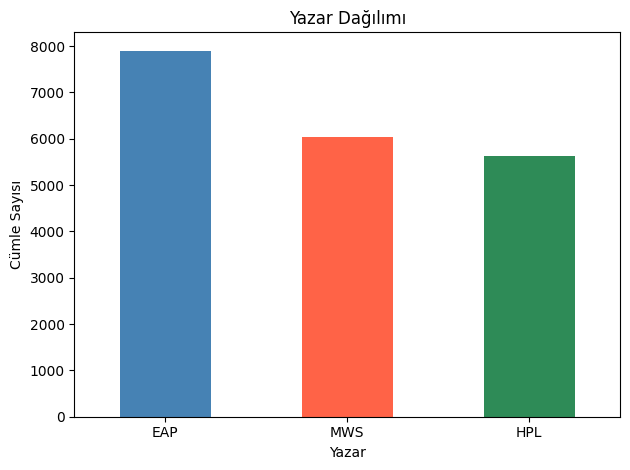

          char_len  word_count
author                        
EAP     142.225949   25.442405
HPL     155.843478   27.799645
MWS     151.659828   27.417273


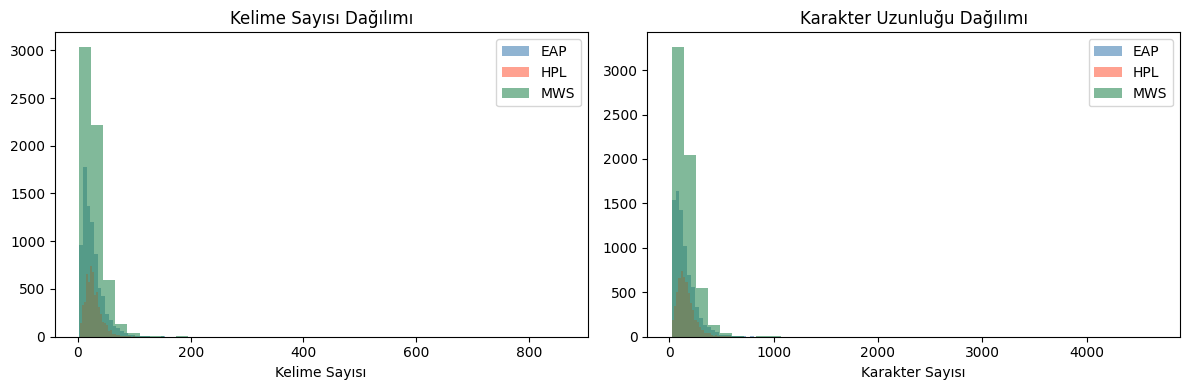

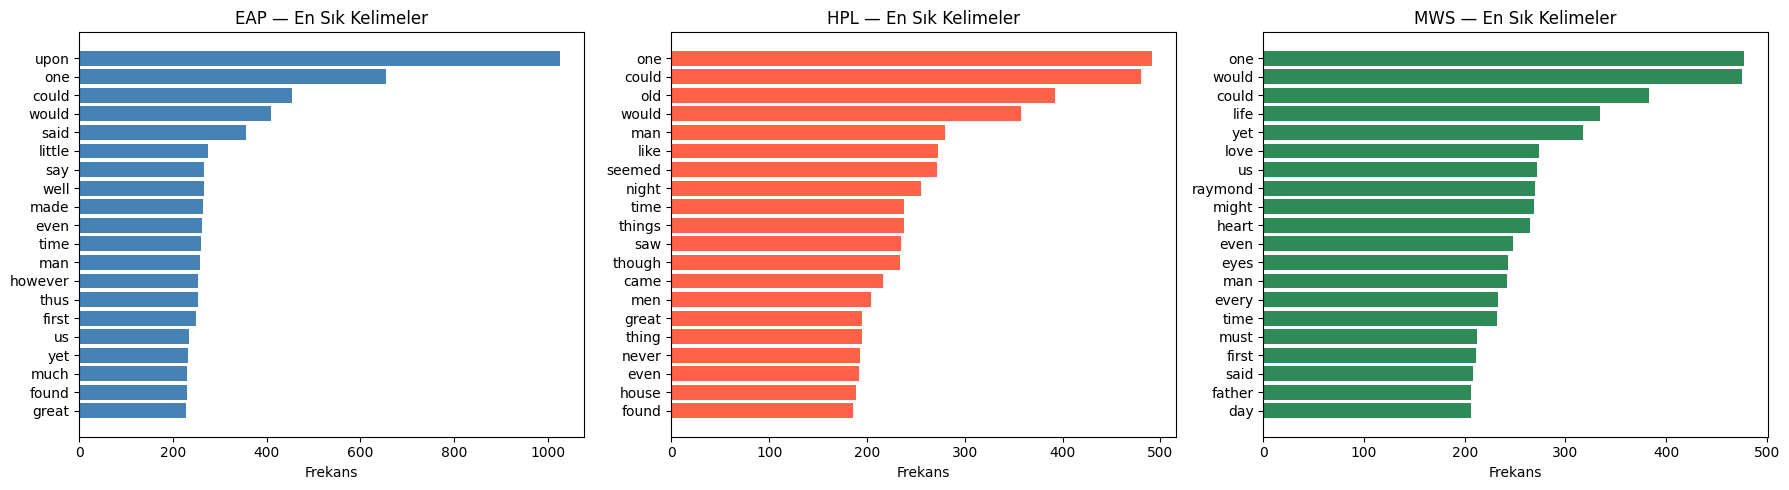

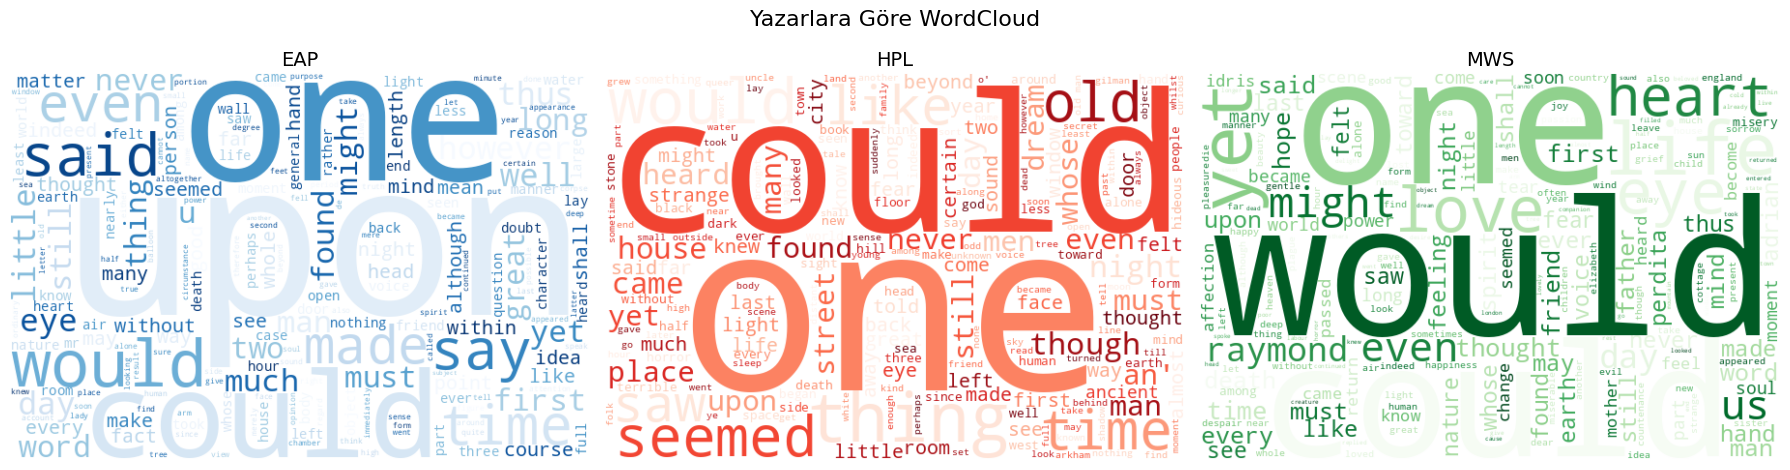

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud
import re

# ── 1. Sınıf Dağılımı ───────────────────────────────────────

df["author"].value_counts().plot(kind="bar", color=["steelblue","tomato","seagreen"])
plt.title("Yazar Dağılımı")
plt.xlabel("Yazar")
plt.ylabel("Cümle Sayısı")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ── 2. Cümle Uzunluğu Analizi ───────────────────────────────

df["char_len"]  = df["text"].apply(len)
df["word_count"] = df["text"].apply(lambda x: len(x.split()))
print(df.groupby("author")[["char_len","word_count"]].mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for author, color in zip(["EAP","HPL","MWS"], ["steelblue","tomato","seagreen"]):
    subset = df[df["author"] == author]
    axes[0].hist(subset["word_count"], bins=40, alpha=0.6, label=author, color=color)
    axes[1].hist(subset["char_len"],   bins=40, alpha=0.6, label=author, color=color)
axes[0].set_title("Kelime Sayısı Dağılımı")
axes[0].set_xlabel("Kelime Sayısı")
axes[0].legend()
axes[1].set_title("Karakter Uzunluğu Dağılımı")
axes[1].set_xlabel("Karakter Sayısı")
axes[1].legend()
plt.tight_layout()
plt.show()

# ── 3. En Sık Kullanılan Kelimeler ──────────────────────────

import nltk
from nltk.corpus import stopwords
nltk.download("stopwords",quiet=True)
stop_words = set(stopwords.words("english"))
def get_top_words(author, n=20):
    texts = df[df["author"] == author]["text"].str.lower()
    words = []
    for t in texts:
        words += [w for w in re.findall(r"\b[a-z]+\b", t) if w not in stop_words]
    return Counter(words).most_common(n)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (author, color) in zip(axes, [("EAP","steelblue"),("HPL","tomato"),("MWS","seagreen")]):
    top = get_top_words(author)
    words, counts = zip(*top)
    ax.barh(words[::-1], counts[::-1], color=color)
    ax.set_title(f"{author} — En Sık Kelimeler")
    ax.set_xlabel("Frekans")
plt.tight_layout()
plt.show()

# ── 4. WordCloud ─────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (author, cmap) in zip(axes, [("EAP","Blues"),("HPL","Reds"),("MWS","Greens")]):
    text = " ".join(df[df["author"] == author]["text"].str.lower())
    wc = WordCloud(
        width=600, height=400,
        stopwords=stop_words,
        background_color="white",
        colormap=cmap
    ).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(author, fontsize=14)
plt.suptitle("Yazarlara Göre WordCloud", fontsize=16)
plt.tight_layout()
plt.show()

# Ön İşleme

Metinleri modellemeye hazırlamak için şu adımları uyguluyoruz:
1. Küçük harfe dönüştürme ve noktalama işaretlerini temizleme
2. İngilizce *stop-words* (anlam yükü düşük bağlaç/edat vb.) kelimelerini çıkarma
3. `WordNetLemmatizer` ile kelimeleri kök haline (lemmatization) getirme
4. Veriyi `%80` eğitim / `%20` test olarak ayırma (`stratify=y` ile her iki kümede sınıf oranları korunur)

In [8]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
def preprocess(text):
    
    text = text.lower()  # Küçük harfe çevir

    text = re.sub(r"[^\w\s]", "", text)  # Noktalama işaretlerini temizle 
    
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words] # Stop words çıkar ve Lemmatization
    
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess)

print(df[["text", "clean_text"]].head(3))

                                                text  \
0  This process, however, afforded me no means of...   
1  It never once occurred to me that the fumbling...   
2  In his left hand was a gold snuff box, from wh...   

                                          clean_text  
0  process however afforded mean ascertaining dim...  
1         never occurred fumbling might mere mistake  
2  left hand gold snuff box capered hill cutting ...  


In [9]:
df.sample(5)

,id,text,author,char_len,word_count,clean_text
16905,id09943,I wandered for ever about these lovely solitud...,MWS,201,35,wandered ever lovely solitude gathering flower...
10811,id01163,"Then he handed the instrument to Morgan, whose...",HPL,64,11,handed instrument morgan whose sight keener
12775,id23236,The Duc slips a card.,EAP,21,5,duc slip card
18310,id26359,Were he not Alexander he would be Diogenes.,EAP,43,8,alexander would diogenes
19389,id09879,I positively felt a wish to explore its depths...,EAP,214,42,positively felt wish explore depth even sacrif...


In [10]:
df.drop(columns=["id","text","char_len","word_count"])

,author,clean_text
0,EAP,process however afforded mean ascertaining dim...
1,HPL,never occurred fumbling might mere mistake
2,EAP,left hand gold snuff box capered hill cutting ...
3,MWS,lovely spring looked windsor terrace sixteen f...
4,HPL,finding nothing else even gold superintendent ...
...,...,...
19574,EAP,could fancied looked eminent landscape painter...
19575,EAP,lid clenched together spasm
19576,EAP,mais il faut agir say frenchman never faint ou...
19577,EAP,item news like strike u coolly received


In [11]:
from sklearn.model_selection import train_test_split
X = df["clean_text"]
y = df["author"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)
print(f"Eğitim Verisi Boyutu : {X_train.shape[0]}")
print(f"Test Verisi Boyutu   : {X_test.shape[0]}")

Eğitim Verisi Boyutu : 15663
Test Verisi Boyutu   : 3916


# Vektörleştirme (TF-IDF)

Temizlenmiş metinleri sayısal özellik matrisine dönüştürmek için `TfidfVectorizer` kullanıyoruz:
- `ngram_range=(1, 2)`: Tekli kelimeler (unigram) ve ardışık kelime ikilileri (bigram) birlikte değerlendirilir.
- `max_features=5000`: En yüksek frekanslı/bilgilendirici 5.000 özellik tutulur.
- `sublinear_tf=True`: Çok sık geçen kelimelerin etkisini logaritmik ölçekle (`1 + log(tf)`) dengeler.
- `min_df=3`: 3'ten az belgede geçen nadir kelimeleri atarak gürültüyü azaltır.

> ⚠️ **Veri Sızıntısı Önlemi:** `fit_transform` yalnızca `X_train` üzerinde, `transform` ise `X_test` üzerinde uygulanır.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2), 
    max_features=5000, 
    sublinear_tf=True,
    min_df=3
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
print(f"Sözlükteki toplam kelime sayısı: {X_train_tfidf.shape[1]}")

Sözlükteki toplam kelime sayısı: 5000


# Model Eğitimi

Metin sınıflandırma problemlerinde hızlı, yorumlanabilir ve yüksek performanslı bir temel (baseline) model olan **Multinomial Naive Bayes** (`MultinomialNB`) eğitiyoruz. `alpha=1.0` parametresi Laplace düzeltmesi (smoothing) uygulayarak eğitim verisinde geçmeyen kelimeler için sıfır olasılık oluşmasını engeller.

In [13]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB(alpha=1.0)

model.fit(X_train_tfidf, y_train)
print("Model başarıyla eğitildi!")

Model başarıyla eğitildi!


# Değerlendirmeler

Bu bölümde eğitilen modelin test seti üzerindeki tahmin performansını **Accuracy**, sınıf bazlı **Precision / Recall / F1-Score** (`classification_report`) ve **Karmaşıklık Matrisi (Confusion Matrix)** üzerinden inceliyor; ayrıca Train ve Test doğruluklarını karşılaştırarak aşırı öğrenme (overfitting) olup olmadığını kontrol ediyoruz.

Test Seti Doğruluğu (Accuracy): %80.31

--- SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

         EAP       0.77      0.86      0.81      1580
         HPL       0.85      0.74      0.79      1127
         MWS       0.82      0.79      0.80      1209

    accuracy                           0.80      3916
   macro avg       0.81      0.80      0.80      3916
weighted avg       0.81      0.80      0.80      3916



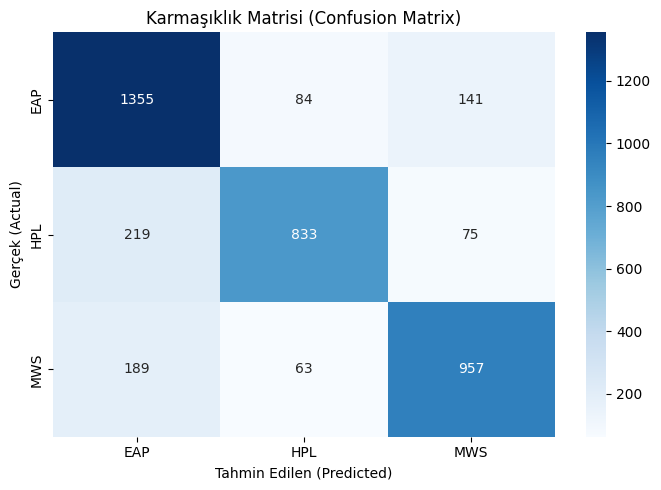

In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_tfidf)

acc = accuracy_score(y_test, y_pred)
print(f"Test Seti Doğruluğu (Accuracy): %{acc * 100:.2f}\n")

print("--- SINIFLANDIRMA RAPORU ---")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=model.classes_, 
            yticklabels=model.classes_)
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.xlabel("Tahmin Edilen (Predicted)")
plt.ylabel("Gerçek (Actual)")
plt.tight_layout()
plt.show()

In [15]:
# Eğitim seti için de tahmin yapalım
y_train_pred = model.predict(X_train_tfidf)
train_acc = accuracy_score(y_train, y_train_pred)

print(f"Eğitim Seti Doğruluğu (Train Accuracy): %{train_acc * 100:.2f}")
print(f"Test Seti Doğruluğu (Test Accuracy)  : %{acc * 100:.2f}")


Eğitim Seti Doğruluğu (Train Accuracy): %86.10
Test Seti Doğruluğu (Test Accuracy)  : %80.31


## 🔄 Cross-Validation (5-Fold) ile Model Doğrulama

Tek bir train/test ayrımına bağımlı kalmadan modelin gerçek genelleme performansını ölçmek için `Pipeline` kullanarak **5-Katlı Çapraz Doğrulama (5-Fold CV)** uyguluyoruz. `Pipeline` yapısı, her katlamada TF-IDF dönüşümünün yalnızca ilgili eğitim katmanına fit edilmesini sağlayarak veri sızıntısını tamamen önler.

In [16]:
# Cross-Validation ile Gerçek Performansı Ölç
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Pipeline: TF-IDF + Model (sızıntısız)
cv_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True, min_df=3)),
    ('model', MultinomialNB(alpha=1.0))
])

X_full = df["clean_text"]
y_full = df["author"]

cv_scores = cross_val_score(cv_pipeline, X_full, y_full, cv=5, scoring='accuracy')
print(f"5-Fold CV Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"CV Scores: {cv_scores}")

5-Fold CV Accuracy: 0.7968 ± 0.0049
CV Scores: [0.79417773 0.79545455 0.79290092 0.79519918 0.8063857 ]


## 🔎 Sınıf Bazlı En Karakteristik Kelimeler

Eğitilmiş `MultinomialNB` modelinin `feature_log_prob_` ağırlıklarını kullanarak her yazar sınıfı (`EAP`, `HPL`, `MWS`) için en yüksek olasılığa sahip karakteristik 10 terimi inceliyoruz.

In [17]:
import numpy as np
import pandas as pd
feature_names = np.array(tfidf.get_feature_names_out())

for i, author in enumerate(model.classes_):
  
    top_indices = np.argsort(model.feature_log_prob_[i])[-10:][::-1]
    top_features = feature_names[top_indices]
    
    print(f"\n🖊️ {author} İçin En Karakteristik 10 Özellik:")
    print(", ".join(top_features))


🖊️ EAP İçin En Karakteristik 10 Özellik:
upon, one, said, could, would, say, however, well, little, time

🖊️ HPL İçin En Karakteristik 10 Özellik:
thing, could, one, old, would, seemed, like, house, man, night

🖊️ MWS İçin En Karakteristik 10 Özellik:
would, one, life, raymond, yet, love, heart, could, day, time


## 📈 Sonuçlar Özeti (Holdout Doğrulama — %20 `train_test_split`)

> **Not:** `Holdout Accuracy` değeri `train.csv` içinden ayrılan %20 holdout doğrulama seti (`3.916` cümle) üzerinde hesaplanmıştır. Doğrulama çalıştırmasında public [abhishek/spooky](https://www.kaggle.com/datasets/abhishek/spooky) veri seti kullanılmıştır.

| Model | Train Accuracy | Holdout Accuracy | 5-Fold CV Accuracy |
|---|---|---|---|
| MultinomialNB (TF-IDF) | %86.10 | %80.31 | **%79.68** (`0.7968 ± 0.0049`) |

## 🔑 Öğrenilen Dersler
1. **TF-IDF sırası kritik:** `fit_transform(X_train)` → `transform(X_test)` — ters yaparsanız data leakage
2. **sublinear_tf=True:** Çok sık geçen kelimelerin etkisini logaritmik olarak dengeler
3. **min_df=3:** 3'ten az belgede geçen kelimeleri atar → gürültü azalır
4. **stratify=y:** Train/holdout ayrımında sınıf oranları korunur